# Solar energy forecasting with SHAPformer (solar with weather)

This notebook trains a SHAPformer model on the **solar_with_weather_1H** dataset from the [fev-bench](https://github.com/autogluon/fev) benchmark: hourly solar power generation together with weather covariates.

1. load the data with the `fev` package,
2. build a dataframe with the covariates of the dataset and calendar features (assuming perfect forecasts of cloud cover and irradiance),
3. inspect the length of the time series and its gaps,
4. split the data into training, validation and test data,
5. train the model (or load a trained one),
6. evaluate the forecasts and explain them.

The switch `TRAINING` decides whether the model is trained from scratch and saved to `MODEL_PATH` (`True`), or whether the trained model is loaded from `MODEL_PATH` (`False`).

In [1]:
%load_ext autoreload
%autoreload 2

import fev
import numpy as np
import pandas as pd
import torch

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from src.models.shapformer import SHAPformer

TRAINING = True  # True: train the model from scratch and save it to MODEL_PATH; False: load the trained model from MODEL_PATH
MODEL_PATH = "solar_model.ckpt"

C:\Users\xk5010\shapformer-2\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the data with fev

We load the task definitions of fev-bench and select the hourly solar task. fev-bench also contains a 15-minute version (`solar_with_weather_15T`) with the same covariates, and two solar datasets without covariates (`solar_1D`, `solar_1W`).

The task distinguishes **known** covariates (available for the forecast horizon) from **past** covariates (only observed up to the forecast start). `task.load_full_dataset()` returns the full dataset as a Hugging Face `datasets.Dataset` with one row per time series.

In [2]:
FEV_BENCH_TASKS = "https://raw.githubusercontent.com/autogluon/fev/main/benchmarks/fev_bench/tasks.yaml"

benchmark = fev.Benchmark.from_yaml(FEV_BENCH_TASKS)
print("Solar tasks:", [t.dataset_config for t in benchmark.tasks if "solar" in t.dataset_config])

task = next(task for task in benchmark.tasks if task.dataset_config == "solar_with_weather_1H")
print(f"Task: {task.task_name}, target: {task.target}, horizon: {task.horizon}, windows: {task.num_windows}")
print(f"Known covariates: {task.known_dynamic_columns}")
print(f"Past covariates:  {task.past_dynamic_columns}")

dataset = task.load_full_dataset(num_proc=1)
dataset

Solar tasks: ['solar_with_weather_15T', 'solar_with_weather_1H', 'solar_1D', 'solar_1W']
Task: solar_with_weather_1H, target: target, horizon: 24, windows: 20
Known covariates: ['day_length', 'humidity', 'pressure', 'rain_1h', 'snow_1h', 'temp', 'wind_speed']
Past covariates:  ['clouds_all', 'global_horizontal_irradiance']


Dataset({
    features: ['id', 'timestamp', 'target', 'global_horizontal_irradiance', 'temp', 'pressure', 'humidity', 'wind_speed', 'rain_1h', 'snow_1h', 'clouds_all', 'day_length'],
    num_rows: 1
})

## Build the dataframe

The dataset contains a single series. The dataframe has one row per hour, indexed by the timestamp. It contains the target `solar` and

- all covariates of the dataset (known and past),
- calendar features: `hour_of_day` and `month`.

Categorical features must be integers starting at 0, so `month` is shifted from 1–12 to 0–11.

In [3]:
series = dataset.to_pandas().iloc[0]
index = pd.DatetimeIndex(series["timestamp"], name="timestamp")

covariates = task.known_dynamic_columns + task.past_dynamic_columns
df = pd.DataFrame({"solar": series["target"], **{c: series[c] for c in covariates}}, index=index)
df["hour_of_day"] = index.hour
df["month"] = index.month - 1  # categorical features must start at 0
print(df)

                      solar  day_length  humidity  pressure  rain_1h  snow_1h  \
timestamp                                                                       
2017-01-01 01:00:00     0.0       450.0     100.0    1020.0      0.0      0.0   
2017-01-01 02:00:00     0.0       450.0     100.0    1020.0      0.0      0.0   
2017-01-01 03:00:00     0.0       450.0     100.0    1019.0      0.0      0.0   
2017-01-01 04:00:00     0.0       450.0     100.0    1018.0      0.0      0.0   
2017-01-01 05:00:00     0.0       450.0     100.0    1017.0      0.0      0.0   
...                     ...         ...       ...       ...      ...      ...   
2022-08-31 12:00:00  7683.0       825.0      57.0    1024.0      0.0      0.0   
2022-08-31 13:00:00  9241.0       825.0      54.0    1024.0      0.0      0.0   
2022-08-31 14:00:00  6201.0       825.0      51.0    1023.0      0.0      0.0   
2022-08-31 15:00:00  4901.0       825.0      52.0    1023.0      0.0      0.0   
2022-08-31 16:00:00  1145.0 

## Length of the time series and covariate statistics

In [4]:
expected = pd.date_range(df.index[0], df.index[-1], freq="h")
print(f"Length: {len(df)} hours ({len(df) / 24 / 365.25:.1f} years), from {df.index[0]} to {df.index[-1]}")
print(f"Missing timestamps: {len(expected.difference(df.index))}")
print(f"Rows with missing covariates: {df[covariates].isna().any(axis=1).sum()}")
df[["solar"] + covariates].describe().T.assign(missing=df.isna().sum())

Length: 49648 hours (5.7 years), from 2017-01-01 01:00:00 to 2022-08-31 16:00:00
Missing timestamps: 0
Rows with missing covariates: 456


,count,mean,std,min,25%,50%,75%,max,missing
solar,49648.0,2271.070557,4066.162598,0.0,0.0,24.000,2393.000000,19008.000000,0
day_length,49192.0,748.648865,194.870697,450.0,570.0,765.000,930.000000,1020.000000,456
humidity,49192.0,79.810539,15.604399,22.0,70.0,84.000,92.000000,100.000000,456
pressure,49192.0,1015.292480,9.585943,977.0,1010.0,1016.000,1021.000000,1047.000000,456
rain_1h,49192.0,0.066038,0.278921,0.0,0.0,0.000,0.000000,8.090000,456
snow_1h,49192.0,0.007148,0.069712,0.0,0.0,0.000,0.000000,2.820000,456
temp,49192.0,9.790511,7.995470,-16.6,3.6,9.300,15.700000,35.799999,456
wind_speed,49192.0,3.937722,1.821740,0.0,2.6,3.700,5.000000,14.300000,456
clouds_all,49192.0,65.973816,36.629288,0.0,34.0,82.000,100.000000,100.000000,456
global_horizontal_irradiance,49192.0,32.597733,51.677307,0.0,0.0,2.875,46.856247,227.824997,456


## Gaps

All covariates are missing in the same rows, which form blocks of whole days. We keep these rows: `fit` only trains and validates on windows of 336 consecutive hours (one week of input and one week of forecast) without missing values. For the evaluation and the explanations below, we also only use forecasts whose input and forecast week are complete.

In [5]:
missing = df[covariates].isna().any(axis=1)
gap_id = (missing != missing.shift()).cumsum()
gaps = [(rows.index[0], rows.index[-1], len(rows)) for _, rows in missing[missing].groupby(gap_id[missing])]
pd.DataFrame(gaps, columns=["first hour", "last hour", "hours"])

,first hour,last hour,hours
0,2017-01-05,2017-01-09 23:00:00,120
1,2019-06-16,2019-06-16 23:00:00,24
2,2021-10-22,2021-10-22 23:00:00,24
3,2021-11-04,2021-11-04 23:00:00,24
4,2021-12-02,2021-12-02 23:00:00,24
5,2021-12-11,2021-12-12 23:00:00,48
6,2021-12-16,2021-12-16 23:00:00,24
7,2021-12-24,2021-12-24 23:00:00,24
8,2022-01-17,2022-01-20 23:00:00,96
9,2022-02-19,2022-02-20 23:00:00,48


## Split the data

The data ends on 31 August 2022. Since solar generation depends strongly on the season, validation and test data cover a full year each:

- the last year (September 2021–August 2022) as test data,
- the year before (September 2020–August 2021) as validation data,
- everything before (January 2017 – August 2020) as training data.

The test data is removed before training, so `fit` only sees the training and validation data.

In [6]:
TEST_START = pd.Timestamp("2021-09-01")
VALIDATION_START = pd.Timestamp("2020-09-01")

train_validation_df = df[df.index < TEST_START]
test_df = df[df.index >= TEST_START]

print(f"Training:   {df.index[0]} to {VALIDATION_START - pd.Timedelta(hours=1)}, "
      f"{(train_validation_df.index < VALIDATION_START).sum()} hours")
print(f"Validation: {VALIDATION_START} to {TEST_START - pd.Timedelta(hours=1)}, "
      f"{(train_validation_df.index >= VALIDATION_START).sum()} hours")
print(f"Test:       {TEST_START} to {df.index[-1]}, {len(test_df)} hours")

Training:   2017-01-01 01:00:00 to 2020-08-31 23:00:00, 32135 hours
Validation: 2020-09-01 00:00:00 to 2021-08-31 23:00:00, 8760 hours
Test:       2021-09-01 00:00:00 to 2022-08-31 16:00:00, 8753 hours


## Create the model

The model predicts `solar` from the covariates in `feature_categories`: for each covariate, the number of categories, or `None` for a continuous feature.

SHAPformer uses the covariates of the forecast week as inputs. In fev-bench, cloud cover (`clouds_all`) and irradiance (`global_horizontal_irradiance`) are past covariates, only observed up to the forecast start. Here, we use them as future covariates anyway: **we assume perfect forecasts of cloud cover and irradiance** for the forecast week, i.e. we use their observed values. The forecast errors below are therefore lower than with real weather forecasts, and not comparable with fev-bench results.

From the known covariates, we use temperature, rain and snow. We drop day length, humidity, pressure and wind speed: day length is determined by the calendar features, and humidity and pressure mainly carry information about cloudiness, which is now given directly by cloud cover and irradiance.

As in the electricity price example, we use a small transformer with one layer, four attention heads and a hidden dimension of 128.

In [7]:
model = SHAPformer(
    target="solar",
    feature_categories={
        "hour_of_day": 24,
        "month": 12,
        "global_horizontal_irradiance": None,  # past covariate, used with perfect forecasts
        "clouds_all": None,  # past covariate, used with perfect forecasts
        "temp": None,
        "rain_1h": None,
        "snow_1h": None,
    },
    d_model=128,
    n_layers=1,
    n_heads=4,
)
print(model.feature_names)

['solar', 'hour_of_day', 'month', 'global_horizontal_irradiance', 'clouds_all', 'temp', 'rain_1h', 'snow_1h']


## Train the model (or load a trained model)

`model.fit(train_validation_df, VALIDATION_START)` trains on the rows before `VALIDATION_START` and computes the validation loss on the rows from `VALIDATION_START` on. Windows with missing values are skipped. Training runs for at most 100 epochs and stops early when the validation loss has not improved for 10 epochs; the model with the lowest validation loss is restored.

With `TRAINING = True`, the trained model is saved to `MODEL_PATH`; with `TRAINING = False`, it is loaded from there.

In [8]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 100

if TRAINING:
    model.to(DEVICE)
    model = model.fit(train_validation_df, VALIDATION_START, epochs=EPOCHS, batch_size=128)
    torch.save(model, MODEL_PATH)
else:
    model = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
    model.eval()

Using 31226 of 31800 training windows; the others contain missing values or missing time steps.


  0%|          | 0/244 [00:00<?, ?it/s]

  0%|          | 1/244 [00:00<01:27,  2.79it/s]

  1%|          | 3/244 [00:00<00:38,  6.20it/s]

  2%|▏         | 5/244 [00:00<00:31,  7.62it/s]

  3%|▎         | 7/244 [00:00<00:27,  8.65it/s]

... (9,030 outputs left out)

100%|█████████▉| 243/244 [00:26<00:00,  8.79it/s]

100%|██████████| 244/244 [00:27<00:00,  8.95it/s]

100%|██████████| 244/244 [00:27<00:00,  9.04it/s]

Epoch 37/100, Training loss: 0.1214943205723997, Validation loss: 0.0473707857959334 (best: 0.04432978999204773), Epochs without improvement: 10/10
Early stopping.
Restored the model from epoch 27 with validation loss 0.04432978999204773.


## Evaluate the model on the validation and test data

For each set, we forecast one week (168 hours) from every midnight whose full forecast week lies within the set and whose input and forecast week have no missing values. We report the mean absolute error (MAE) and the root mean squared error (RMSE) in the unit of the target (not documented in the dataset), over the full week and over the first 24 hours (the horizon of the fev-bench task). As references, we compare with two seasonal naive forecasts: the daily naive forecast repeats the last day of the input seven times, the weekly naive forecast repeats the last week.

In [9]:
INPUT_LENGTH = HORIZON = 168

# complete[p]: the forecast from row p has no missing values in its input and forecast week
missing_sum = np.concatenate(([0], np.cumsum(df[model.feature_names].isna().any(axis=1).to_numpy())))


def complete(p):
    return p >= INPUT_LENGTH and p + HORIZON <= len(df) and missing_sum[p + HORIZON] == missing_sum[p - INPUT_LENGTH]


def evaluate(start_time, end_time):
    # forecasts from every midnight in [start_time, end_time) whose forecast week ends before end_time
    positions = np.flatnonzero((df.index >= start_time) & (df.index < end_time) & (df.index.hour == 0))
    positions = [p for p in positions if complete(p) and df.index[p + HORIZON - 1] < end_time]
    actual, model_forecast, daily_forecast, weekly_forecast = [], [], [], []
    for p in positions:
        past, future = df.iloc[p - INPUT_LENGTH:p], df.iloc[p:p + HORIZON]
        actual.append(future["solar"].to_numpy())
        model_forecast.append(model.predict(past, future.drop(columns="solar")).to_numpy())
        daily_forecast.append(np.tile(past["solar"].to_numpy()[-24:], 7))
        weekly_forecast.append(past["solar"].to_numpy())
    actual = np.array(actual)
    rows = {}
    for name, forecast in [("SHAPformer", model_forecast), ("Daily naive", daily_forecast),
                           ("Weekly naive", weekly_forecast)]:
        error = np.array(forecast) - actual
        rows[name] = {
            "MAE (168 h)": np.abs(error).mean(),
            "RMSE (168 h)": np.sqrt((error ** 2).mean()),
            "MAE (24 h)": np.abs(error[:, :24]).mean(),
            "RMSE (24 h)": np.sqrt((error[:, :24] ** 2).mean()),
        }
    return pd.DataFrame(rows).T, len(positions)


results = {}
for name, start_time, end_time in [("Validation", VALIDATION_START, TEST_START),
                                   ("Test", TEST_START, df.index[-1] + pd.Timedelta(hours=1))]:
    results[name], n_forecasts = evaluate(start_time, end_time)
    print(f"{name}: {n_forecasts} forecasts")
pd.concat(results).astype(float).round(1)

Validation: 359 forecasts


Test: 263 forecasts


MAE (168 h)  RMSE (168 h)  MAE (24 h)  RMSE (24 h)
Validation SHAPformer          406.5         871.2       396.4        867.1
           Daily naive        1316.6        2964.3      1177.0       2746.3
           Weekly naive       1369.7        3042.2      1370.3       3042.6
Test       SHAPformer          471.0        1083.2       461.7       1088.2
           Daily naive        1468.1        3183.7      1210.6       2742.7
           Weekly naive       1582.9        3358.6      1572.2       3346.1

## Explain one forecast

We explain the forecast of the week starting on Monday, 13 June 2022 (test data). `model.explain(past, future)` splits the forecast into contributions of feature groups: one group per covariate, and one group per day of the past solar generation (`day 1` is the oldest day, `day 7` the most recent one). `base` + the sum of all contributions = `prediction`. For a single forecast, we use the exact method (`method="exact"`), which evaluates the model with all 2<sup>14</sup> feature group subsets.

The explanation is plotted as a stacked area chart around the base value (dotted): positive contributions are stacked above the base, negative ones below it, so the forecast (solid line) lies between the upper and the lower edge of the stack. The dashed line is the actual generation.

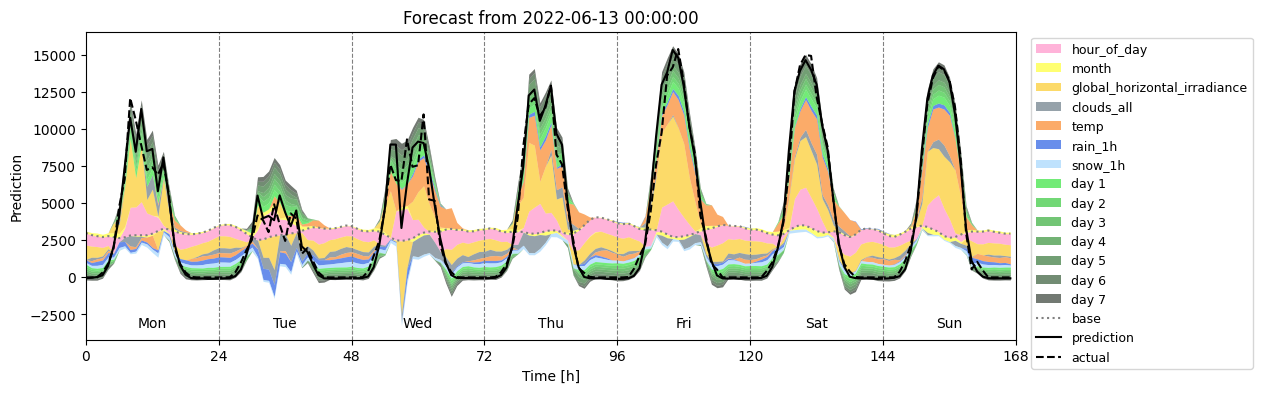

In [10]:
import matplotlib.pyplot as plt
from src.plot import plot_explanation

FORECAST_START = "2022-06-13 00:00:00"
UNIT = ""  # the unit of the target is not documented in the dataset

start = df.index.get_loc(FORECAST_START)
assert complete(start)
past = df.iloc[start - INPUT_LENGTH:start]
future = df.iloc[start:start + HORIZON].drop(columns="solar")
actual = df["solar"].iloc[start:start + HORIZON]

explanation = model.explain(past, future, method="exact", progress=False)
plot_explanation(explanation, actual=actual, unit=UNIT, title=f"Forecast from {FORECAST_START}")
plt.show()

## Dependence plots of 1000 explanations

We explain 1000 forecasts with random starts (at any hour) in the validation and test period (September 2020 – August 2022), so that all months are covered, skipping forecasts with missing values. We use the fast approximate method `method="permutation"`: it estimates the Owen values from `N_PERMUTATIONS` random orders of the feature groups (each explanation with its own seed for reproducibility), instead of evaluating all 2<sup>14</sup> feature group subsets. `progress=False` turns off the progress bar of each single explanation; instead, one progress bar shows the progress over all explanations.

A dependence plot shows, for one feature, how its value relates to its contribution: each dot is one explained forecast, with the feature value on the x-axis and its SHAP value at the forecasted hour `DEPENDENCE_HORIZON` (here the 24th hour) on the y-axis. For the solar generation, the x-axis is the generation one week before that hour, and the y-axis the sum of the contributions of all seven past days. For categorical features, the red line shows the mean contribution per category.

In [11]:
import math
import random
from tqdm import tqdm
from src.plot import plot_dependence

SEED = 42
N_EXPLANATIONS = 1000
N_PERMUTATIONS = 10  # permutations per explanation
DEPENDENCE_HORIZON = 24  # plot the SHAP values of the 24th predicted hour; None plots all 168 hours
N_COLUMNS = 4

# random complete forecast starts in the validation and test period;
# the past week of the first starts reaches into the training period
first_validation_start = int((df.index < VALIDATION_START).sum())
candidates = [p for p in range(first_validation_start, len(df) - HORIZON + 1) if complete(p)]
starts = random.Random(SEED).sample(candidates, N_EXPLANATIONS)

explanations = [
    model.explain(df.iloc[s - INPUT_LENGTH:s], df.iloc[s:s + HORIZON].drop(columns="solar"),
                  method="permutation", n_permutations=N_PERMUTATIONS, seed=SEED + i, progress=False)
    for i, s in enumerate(tqdm(starts, desc="Explanations"))
]

Explanations:   0%|          | 0/1000 [00:00<?, ?it/s]

Explanations:   0%|          | 1/1000 [00:00<02:04,  8.02it/s]

Explanations:   0%|          | 2/1000 [00:00<01:58,  8.42it/s]

Explanations:   0%|          | 3/1000 [00:00<01:56,  8.55it/s]

Explanations:   0%|          | 4/1000 [00:00<01:56,  8.58it/s]

Explanations:   0%|          | 5/1000 [00:00<01:55,  8.62it/s]

... (980 outputs left out)

Explanations: 100%|█████████▉| 998/1000 [01:44<00:00,  9.57it/s]

Explanations: 100%|█████████▉| 999/1000 [01:44<00:00,  9.62it/s]

Explanations: 100%|██████████| 1000/1000 [01:44<00:00,  9.65it/s]

Explanations: 100%|██████████| 1000/1000 [01:44<00:00,  9.54it/s]

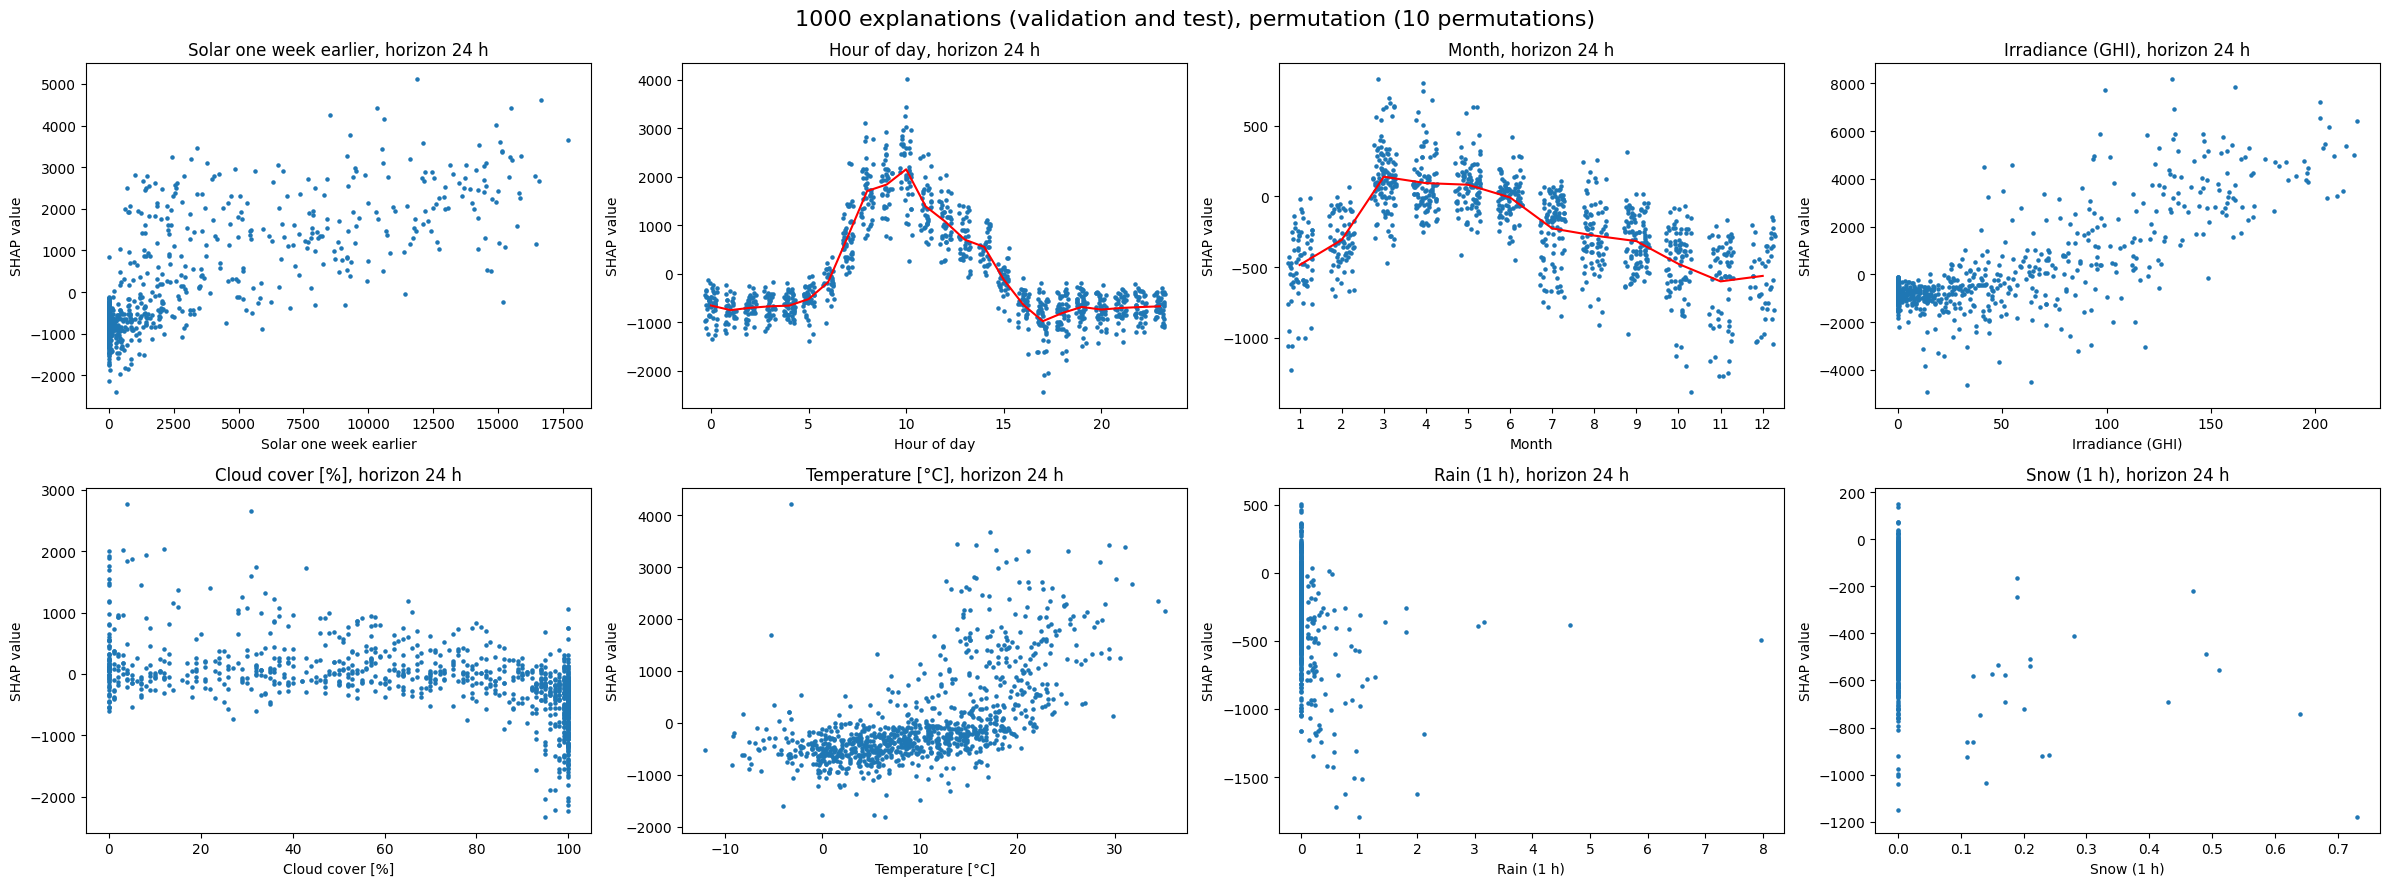

In [12]:
n_rows = math.ceil(len(model.feature_names) / N_COLUMNS)
fig, axs = plt.subplots(n_rows, N_COLUMNS, figsize=(6 * N_COLUMNS, 4.5 * n_rows))
for ax, feature in zip(axs.flat, model.feature_names):
    plot_dependence(explanations, feature, horizon=DEPENDENCE_HORIZON, unit=UNIT, ax=ax)
for ax in axs.flat[len(model.feature_names):]:
    ax.set_visible(False)
fig.suptitle(f"{N_EXPLANATIONS} explanations (validation and test), permutation ({N_PERMUTATIONS} permutations)", fontsize=16)
fig.tight_layout()
plt.show()